<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 22: Independent Component Analysis and Component Visualization

**Category**: CO4 – Linear Factor Models and Probabilistic Graphical Models  
**Objective**: Perform blind source separation on linearly superimposed non-Gaussian audio/sensor streams using FastICA.


### Task 1: Synthesize Independent Non-Gaussian Signals and Linear Mixing


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.decomposition import FastICA

np.random.seed(42)
n_samples = 1500
t = np.linspace(0, 8, n_samples)

# 3 Original source signals: Sine, Sawtooth, and Random Noise
s1 = np.sin(2 * t)                         # Sinusoidal
s2 = signal.sawtooth(2 * np.pi * t)        # Sawtooth
s3 = np.random.uniform(-1, 1, n_samples)   # Uniform noise

S_true = np.c_[s1, s2, s3]
S_true /= S_true.std(axis=0)

# Linear mixing matrix A (3x3)
A_mix = np.array([
    [0.7, 0.5, 0.4],
    [0.4, 0.9, 0.2],
    [0.3, 0.3, 0.8]
])

X_mixed = np.dot(S_true, A_mix.T)
print("Source Signals Shape:", S_true.shape)
print("Mixed Observations Shape:", X_mixed.shape)


Source Signals Shape: (1500, 3)
Mixed Observations Shape: (1500, 3)


### Task 2: Blind Source Separation via FastICA


In [2]:
ica = FastICA(n_components=3, random_state=42)
S_recovered = ica.fit_transform(X_mixed)
S_recovered /= S_recovered.std(axis=0)

print("FastICA Converged Successfully. Unmixing Matrix W Shape:", ica.components_.shape)


FastICA Converged Successfully. Unmixing Matrix W Shape: (3, 3)


### Task 3: Waveform Visualizations: Original vs. Mixed vs. Recovered


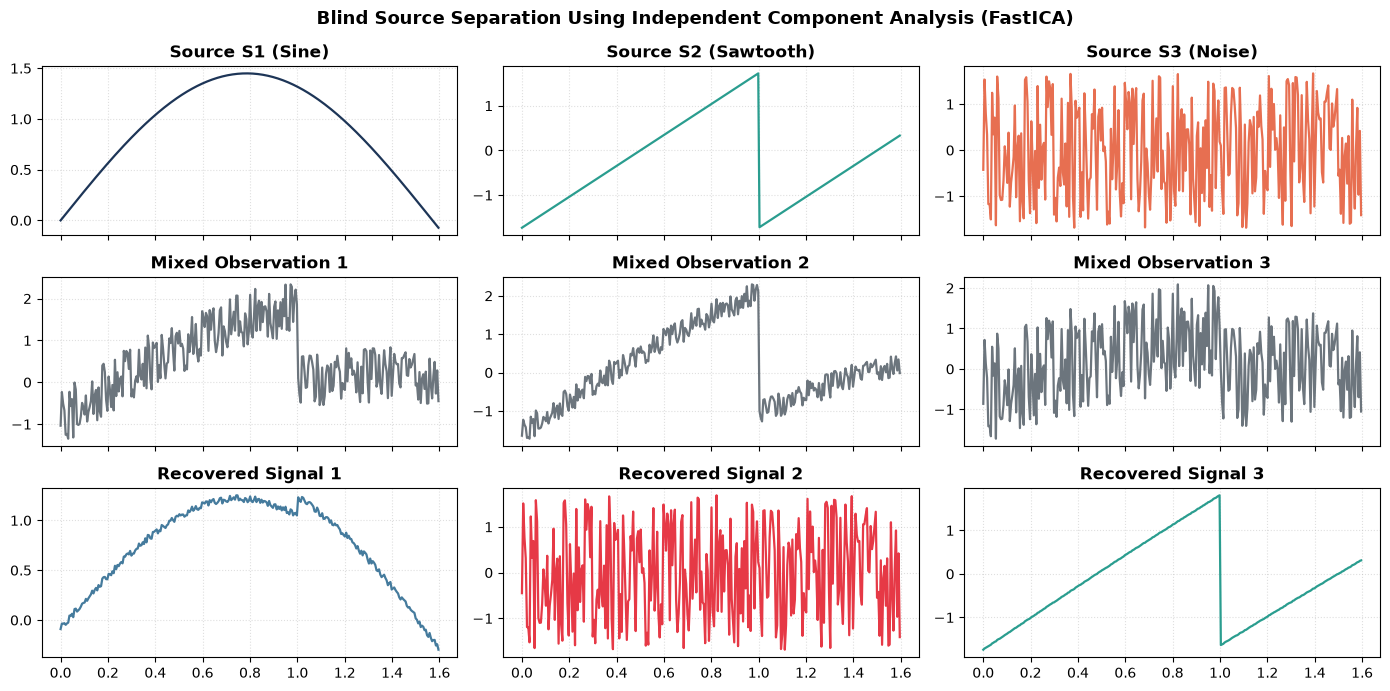

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(14, 7), sharex=True)

titles = ["Source S1 (Sine)", "Source S2 (Sawtooth)", "Source S3 (Noise)",
          "Mixed Observation 1", "Mixed Observation 2", "Mixed Observation 3",
          "Recovered Signal 1", "Recovered Signal 2", "Recovered Signal 3"]

colors = ['#1d3557', '#2a9d8f', '#e76f51',
          '#6c757d', '#6c757d', '#6c757d',
          '#457b9d', '#e63946', '#2a9d8f']

for i in range(3):
    axes[0, i].plot(t[:300], S_true[:300, i], color=colors[i], lw=1.6)
    axes[0, i].set_title(titles[i], fontweight='bold')
    axes[0, i].grid(True, linestyle=':', alpha=0.4)

    axes[1, i].plot(t[:300], X_mixed[:300, i], color=colors[3+i], lw=1.6)
    axes[1, i].set_title(titles[3+i], fontweight='bold')
    axes[1, i].grid(True, linestyle=':', alpha=0.4)

    axes[2, i].plot(t[:300], S_recovered[:300, i], color=colors[6+i], lw=1.6)
    axes[2, i].set_title(titles[6+i], fontweight='bold')
    axes[2, i].grid(True, linestyle=':', alpha=0.4)

plt.suptitle("Blind Source Separation Using Independent Component Analysis (FastICA)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
